# metawalker demo

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/drive/1nKxKFCsVaD7sqL6rE6NkNPjR3K4qFE5y?usp=sharing)

**The claim:** some objectives are flat almost everywhere, with the signal hidden in a small region. Searching
for reward-hacking honeypots is one example, because nearly every setting scores zero. Standard optimizers have
nothing to follow there. `metawalker`'s learned walker was trained to explore until it finds signal, then home in.

This notebook checks that claim on a synthetic example, then shows how to use it on your own function and as a scikit-learn search.
Run all cells (Runtime → Run all). It takes a few minutes, mostly in section 3.

In [1]:
!pip install -q "metawalker>=0.2.2"
import numpy as np, matplotlib.pyplot as plt
import metawalker as mw

## 1. Finding a hidden region

A 50-parameter function that equals 1.0 almost everywhere, with a little noise. Its minimum (0) sits inside a small
pocket. Each optimizer gets 300 evaluations, and we repeat that with 20 different seeds. A run **found the region**
if it ends below 0.1.

> **What to look for:**
> - **Left:** the blue line drops below the dashed line, at about 200 evaluations for the median run. Orange and gray stay well above it.
> - **Right:** the learned walker finds the region in about two thirds of runs. CMA-ES and random search almost never do.

learned walker  found the region in 13 / 20 runs
CMA-ES          found the region in  2 / 20 runs
random search   found the region in  0 / 20 runs


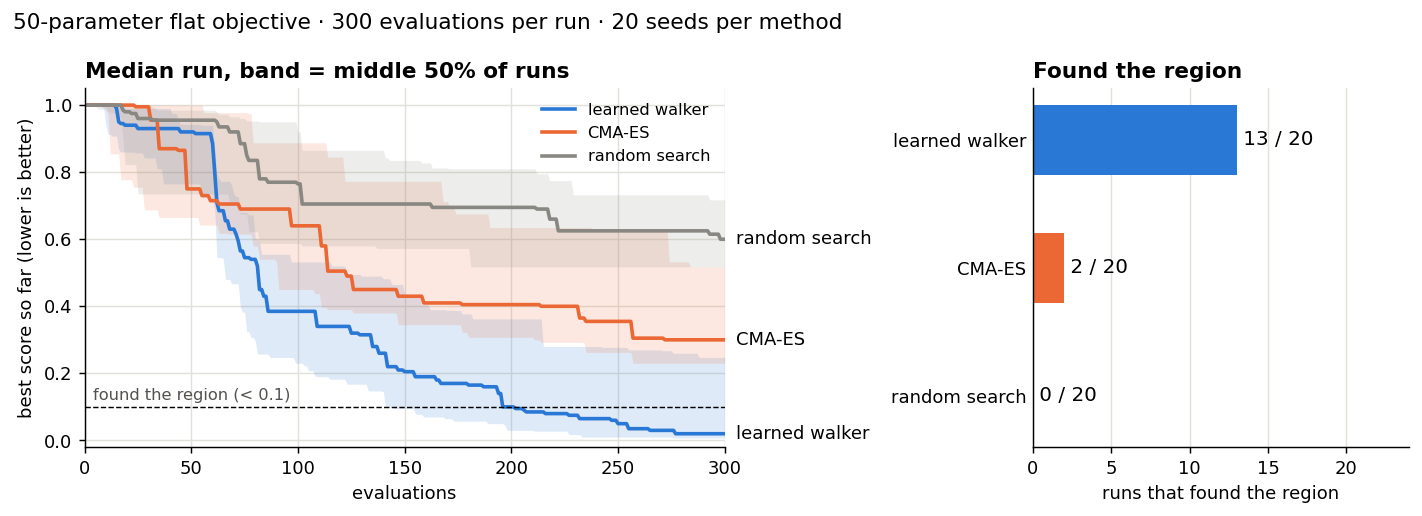

In [2]:
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e1e0d9", "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlelocation": "left"})
fn, space = mw.make_problem("plateau", n=50, seed=1, noise=0.01)
methods = {"learned walker": ("walker_hp_warm", "#2a78d6"), "CMA-ES": ("cmaes", "#eb6834"), "random search": ("random", "#898781")}
BUDGET, SEEDS, FOUND = 300, 20, 0.1

curves, hits = {}, {}
for name, (m, _) in methods.items():
    runs = [mw.minimize(fn, space, budget=BUDGET, method=m, seed=s) for s in range(SEEDS)]
    curves[name] = np.array([np.minimum.accumulate([y for _, y in r.history]) for r in runs])  # best so far
    hits[name] = int((curves[name][:, -1] < FOUND).sum())
    print(f"{name:15s} found the region in {hits[name]:2d} / {SEEDS} runs")

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1.7, 1]})
for name, (_, color) in methods.items():
    lo, med, hi = np.percentile(curves[name], [25, 50, 75], axis=0)
    left.fill_between(range(1, BUDGET + 1), lo, hi, color=color, alpha=0.15, linewidth=0)
    left.plot(range(1, BUDGET + 1), med, color=color, linewidth=2, label=name)
    left.annotate(name, (BUDGET, med[-1]), xytext=(6, 0), textcoords="offset points", va="center")
left.axhline(FOUND, color="black", linewidth=0.8, linestyle="--")
left.text(4, FOUND + 0.02, "found the region (< 0.1)", fontsize=9, color="#52514e")
left.set(xlim=(0, BUDGET), ylim=(-0.02, 1.05), xlabel="evaluations",
         ylabel="best score so far (lower is better)", title="Median run, band = middle 50% of runs")
left.legend(frameon=False, loc="upper right", fontsize=9)

names = list(methods)[::-1]
bars = right.barh(names, [hits[n] for n in names], color=[methods[n][1] for n in names], height=0.55)
right.bar_label(bars, labels=[f" {hits[n]} / {SEEDS}" for n in names], fontsize=11)
right.set(xlim=(0, SEEDS * 1.2), xlabel="runs that found the region", title="Found the region")
right.grid(axis="y", visible=False); right.tick_params(axis="y", length=0)
fig.suptitle(f"50-parameter flat objective · {BUDGET} evaluations per run · {SEEDS} seeds per method", x=0.01, ha="left")
fig.tight_layout(); plt.show()

**Why:** CMA-ES adapts to the shape of the landscape, and a flat landscape has no shape, so it shrinks in place.
Random search samples blindly. The walker jumps around until something scores below 1, then switches to small
local steps.

**Fair warning:** this test problem comes from the same family the walker was trained on, so this is its best case.
Without its warm-up phase (`method="walker_hp"`), the walker finds it much less often. On ordinary
smooth problems it roughly ties CMA-ES. On a real 169-parameter honeypot search, it reached its first strong level
in a median of 6 PPO runs, against 17 for CMA-ES.

## 2. Use it on your own function

Write a function that takes a dict of parameters and returns a number. Here it's a made-up validation loss whose
best settings are known: lr = 0.001, 5 layers, gelu.

> **What to look for:** the `found` column should match the `true` column, from 200 evaluations.

In [3]:
def val_loss(p):
    return (np.log10(p["lr"]) + 3) ** 2 + 0.1 * (p["layers"] - 5) ** 2 + {"relu": 0.2, "gelu": 0, "tanh": 0.5}[p["act"]]

space = {"lr": mw.Float(1e-5, 1e-1, log=True), "layers": mw.Int(1, 8), "act": ["relu", "gelu", "tanh"]}

result = mw.minimize(val_loss, space, budget=200, method="panel", seed=0)

truth = {"lr": 0.001, "layers": 5, "act": "gelu"}
show = lambda v: f"{v:.4g}" if isinstance(v, float) else v
print(f"{'':8s}{'found':>10s}{'true':>10s}")
for k in truth:
    print(f"{k:8s}{show(result.best_params[k]):>10}{show(truth[k]):>10}")

             found      true
lr       0.0009971     0.001
layers           5         5
act           gelu      gelu


`method="panel"` splits the budget between the learned walker, a learned CMA-ES and plain CMA-ES, then keeps the
best result. Use it when you don't know what your landscape looks like. Pass `maximize=True` if higher is better.

## 3. Beating `RandomizedSearchCV` when there are many hyperparameters

`MetaWalkerCV` is a drop-in for scikit-learn's `GridSearchCV` / `RandomizedSearchCV`: same `cv`, `scoring`,
`best_params_`, `best_estimator_`. With 2 or 3 hyperparameters, random search is already close to optimal, so
there's nothing to win. The gap opens up when there are dozens.

The test: a nearest-neighbour classifier with **one weight per feature** (40 weights to tune). Only 6 of the 40
features carry signal, so a good search has to learn to turn the other 34 down. Each search gets 300 tries,
with 5 seeds each, and are scored on a held-out test set they never saw.

> **What to look for:** both blue rows (`MetaWalkerCV`) sit to the right of the gray one (`RandomizedSearchCV`).
> The default method gets about 0.91, `rlbo` about 0.93, random search about 0.88. This cell takes a few minutes.

In [4]:
from scipy.stats import uniform
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.datasets import make_classification
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from metawalker.sklearn import MetaWalkerCV

class WeightedKNN(ClassifierMixin, BaseEstimator):
    """5-nearest-neighbours after multiplying feature i by weight w_i: one hyperparameter per feature."""
    def __init__(self, d=40, **w):
        self.d = d
        for i in range(d): setattr(self, f"w{i}", w.get(f"w{i}", 1.0))
    def get_params(self, deep=True):
        return {"d": self.d, **{f"w{i}": getattr(self, f"w{i}") for i in range(self.d)}}
    def set_params(self, **p):
        for k, v in p.items(): setattr(self, k, v)
        return self
    def fit(self, X, y):
        self.w_ = np.array([getattr(self, f"w{i}") for i in range(self.d)])
        self.knn_ = KNeighborsClassifier(5).fit(X * self.w_, y); self.classes_ = self.knn_.classes_
        return self
    def predict(self, X):
        return self.knn_.predict(X * self.w_)

In [ ]:
D, TRIES, SEEDS = 40, 300, 5
X, y = make_classification(n_samples=3000, n_features=D, n_informative=6, n_redundant=0, random_state=0)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, random_state=0)

searches = {
    "RandomizedSearchCV": lambda s: RandomizedSearchCV(WeightedKNN(D), {f"w{i}": uniform(0, 1) for i in range(D)},
                                                       n_iter=TRIES, cv=3, random_state=s, n_jobs=-1),
    "MetaWalkerCV (auto)": lambda s: MetaWalkerCV(WeightedKNN(D), {f"w{i}": mw.Float(0, 1) for i in range(D)},
                                                  n_iter=TRIES, cv=3, random_state=s, n_jobs=-1),
    "MetaWalkerCV (rlbo)": lambda s: MetaWalkerCV(WeightedKNN(D), {f"w{i}": mw.Float(0, 1) for i in range(D)},
                                                  n_iter=TRIES, method="rlbo", cv=3, random_state=s, n_jobs=-1),
}
test = {}
for name, make in searches.items():
    test[name] = [make(s).fit(X_tr, y_tr).score(X_te, y_te) for s in range(SEEDS)]
    print(f"{name:20s} test accuracy {np.mean(test[name]):.3f}   per seed {np.round(test[name], 3)}")

colors = {"RandomizedSearchCV": "#898781", "MetaWalkerCV (auto)": "#86b6ef", "MetaWalkerCV (rlbo)": "#2a78d6"}
fig, ax = plt.subplots(figsize=(8, 3.2))
for row, (name, accs) in enumerate(test.items()):
    ax.scatter(accs, [row] * SEEDS, s=70, color=colors[name], zorder=3)
    ax.plot([np.mean(accs)] * 2, [row - 0.25, row + 0.25], color="black", linewidth=2)
    ax.annotate(f"mean {np.mean(accs):.3f}", (np.mean(accs), row + 0.3), ha="center", fontsize=9)
ax.set(yticks=range(len(test)), yticklabels=list(test), ylim=(-0.6, len(test) - 0.3), xlabel="test accuracy (each dot = one seed)",
       title=f"{D} hyperparameters, {TRIES} tries each")
ax.grid(axis="y", visible=False); ax.tick_params(axis="y", length=0)
fig.tight_layout(); plt.show()

**Where the gain comes from:** plain CMA-ES (`method="cmaes"`) scored about 0.907 in our runs, so much of the gap
comes from searching in a guided way at all. The default (a learned CMA-ES) adds a little, and `rlbo`, the method
that found the strongest honeypots in the write-up, adds about two more points. For a small search, such as an
SVC's `C` and `gamma`, we found no difference from random search.

## More

- `mw.compare(...)`: test several methods on your own losses. `res.success_table()`, `res.plot()` and
  `res.suggest_panel()` show how often and how fast each one gets there, and which to use.
- `mw.certify(fn, result)`: re-check the best result on a noisy objective, with a confidence interval.
- `mw.importance(result)`: which parameters mattered, from the search history.
- `mw.register("mine", my_optimizer)`: add your own trained walker, or any function (grid search, say), as a method name that works in `minimize`, panels, `compare` and `MetaWalkerCV`.

Details and benchmarks: [PyPI](https://pypi.org/project/metawalker/) ·
[GitHub](https://github.com/Itsme-aniketghosh/MetaWalker)